# 02, compréhension des données

Phase 2 de CRISP-DM, résumée dans `docs/donnees.md`. Ce notebook appelle les fonctions de `moteur/donnees.py` et `moteur/controles.py` et affiche leurs résultats, sans calcul propre. Les séries absentes de `data/raw` sont téléchargées au premier passage. Les chiffres cités dans les cellules de texte sont ceux que ces cellules affichent.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from moteur.controles import (DEBUT_SERIES, FIN_SERIES, case_la_plus_arrosee, charger_lieu, climatologie_mensuelle,
                              comparer_pluies, comparer_station, comparer_tmax_station, controler_serie,
                              dispersion_voisinage, ecart_case_moyenne, essai_resolution_imerg, jours_par_annee,
                              rupture_rapport)
from moteur.donnees import DOSSIER_POWER, nom_fichier, parametres_entete
from moteur.lieux import LIEUX

pd.set_option("display.precision", 3)
series = {identifiant: charger_lieu(identifiant) for identifiant in LIEUX}
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}

## 1. Résolution et étiquette de la pluie IMERG

La pluie IMERG est lue par l'API NASA POWER. L'essai compare trois points du 1er au 10 août 2025, deux dans la même case de 0,1 degré et un dans la case voisine au nord. La seconde cellule affiche la description que l'en-tête du fichier POWER donne du paramètre.

In [2]:
display(essai_resolution_imerg())
case_korhogo = series["korhogo"]["cases"][0]
parametres_entete(DOSSIER_POWER / nom_fichier("imerg", *case_korhogo))

,"case 9,4 à 9,5 et -5,7 à -5,6, premier point","même case, second point",case voisine au nord
date,,,
2025-08-01,2.25,2.25,4.84
2025-08-02,0.27,0.27,0.00
2025-08-03,0.00,0.00,0.00
2025-08-04,3.11,3.11,25.83
2025-08-05,0.27,0.27,0.41
2025-08-06,0.00,0.00,0.00
2025-08-07,7.54,7.54,5.39
2025-08-08,0.86,0.86,1.47
2025-08-09,1.88,1.88,3.40


{'IMERG_PRECTOT': 'MERRA-2 Total Precipitation (mm/day)'}

**Constat.** Les deux points de la même case reçoivent exactement la même pluie chaque jour, alors que la case voisine diffère, avec par exemple 3,11 mm contre 25,83 mm le 4 août. L'en-tête décrit pourtant `IMERG_PRECTOT` comme « MERRA-2 Total Precipitation ».

**Analyse.** POWER sert donc IMERG à sa résolution native de 0,1 degré, bien plus fine que la maille de 0,5 par 0,625 degré de MERRA-2. Les métadonnées officielles de l'API définissent ce paramètre comme la pluie totale d'IMERG, si bien que l'en-tête est faux et non la donnée.

**Décision.** IMERG est la pluie retenue, lue case par case, et l'erreur d'étiquette est signalée dans `docs/donnees.md`.

## 2. Couverture, manques et bornes physiques

Chaque série est contrôlée de 2001 à 2025, nombre de jours, dates manquantes ou en double, valeurs manquantes, extrêmes et violations de bornes physiques.

In [3]:
couverture = {}
for identifiant, s in series.items():
    couverture[f"{noms[identifiant]}, POWER"] = controler_serie(s["power"], LIEUX[identifiant]["lat"], DEBUT_SERIES, FIN_SERIES)
    couverture[f"{noms[identifiant]}, IMERG case du lieu"] = controler_serie(
        s["imerg"][s["cases"][0]].to_frame(), LIEUX[identifiant]["lat"], DEBUT_SERIES, FIN_SERIES)
pd.DataFrame(couverture)

,"Korhogo, POWER","Korhogo, IMERG case du lieu","Bouaké, POWER","Bouaké, IMERG case du lieu"
jours,9131,9131,9131,9131
jours_attendus,9131,9131,9131,9131
dates_uniques,True,True,True,True
dates_manquantes,0,0,0,0
T2M_MAX manquants,0,NaN,0,NaN
T2M_MAX min,24.1,NaN,24.27,NaN
T2M_MAX max,42.55,NaN,40.78,NaN
T2M_MIN manquants,0,NaN,0,NaN
T2M_MIN min,11.19,NaN,12.02,NaN
T2M_MIN max,28.67,NaN,26.64,NaN


**Constat.** Les 9 131 jours de 2001 à 2025 sont présents pour chaque série aux deux lieux, sans date manquante ni en double et sans valeur manquante. Aucune pluie, aucun vent ni aucun rayonnement n'est négatif, aucun minimum de température ne dépasse le maximum, aucun point de rosée ne dépasse la température maximale, aucun rayonnement ne dépasse le rayonnement extraterrestre de FAO-56, et aucune pluie journalière ne dépasse 200 mm.

**Analyse.** Les séries sont complètes et physiquement possibles. Ces contrôles ne disent rien de leur justesse, que seule la comparaison à d'autres sources peut approcher.

**Décision.** Aucune valeur n'est corrigée ni écartée. La justesse est examinée dans les sections suivantes.

## 3. Pluie IMERG et pluie PRECTOTCORR de POWER

La pluie est comparée entre deux sources, IMERG et la pluie corrigée `PRECTOTCORR` de MERRA-2, par année, en cumul, en rapport et en corrélation journalière.

Korhogo                                                  Bouaké  \
     imerg_mm prectotcorr_mm rapport correlation_journaliere imerg_mm   
date                                                                    
2001  1009.96         850.57   0.842                   0.303   846.15   
2002  1039.12         786.79   0.757                   0.310  1120.02   
2003  1303.27         926.44   0.711                   0.434  1239.56   
2004  1210.80         791.76   0.654                   0.232  1057.04   
2005  1189.90         816.90   0.687                   0.286   884.71   
2006  1185.73         834.05   0.703                   0.325  1020.14   
2007  1250.48         847.72   0.678                   0.500   882.53   
2008  1229.72        1026.29   0.835                   0.342  1089.72   
2009  1304.42        1026.13   0.787                   0.300  1121.97   
2010  1248.66        1238.31   0.992                   0.407  1260.97   
2011  1254.97         969.90   0.773                   0.286  1012.76   
2012  1413.80        1159.26   0.820                   0.291  1180.19   
2013  1358.64         959.98   0.707                   0.273  1179.54   
2014  1347.43        1188.51   0.882                   0.409  1173.32   
2015  1042.14         843.78   0.810                   0.191   840.45   
2016  1212.85         925.88   0.763                   0.342  1062.58   
2017  1186.66         936.92   0.790                   0.508  1094.83   
2018  1460.83        1358.09   0.930                   0.435  1735.56   
2019  1393.67        1273.39   0.914                   0.460  1386.62   
2020  1236.95        1143.20   0.924                   0.518  1032.85   
2021  1462.73        1191.61   0.815                   0.225  1184.66   
2022  1128.84        1094.21   0.969                   0.357  1194.06   
2023  1123.99         884.88   0.787                   0.270  1231.16   
2024  1427.80         847.79   0.594                   0.550  1106.14   
2025  1187.43         739.78   0.623                   0.233  1389.70   

                                                     
     prectotcorr_mm rapport correlation_journaliere  
date                                                 
2001        1122.76   1.327                   0.258  
2002         995.14   0.889                   0.388  
2003        1236.58   0.998                   0.362  
2004        1194.96   1.130                   0.334  
2005        1181.05   1.335                   0.402  
2006        1181.30   1.158                   0.346  
2007        1093.32   1.239                   0.442  
2008        1249.82   1.147                   0.414  
2009        1381.19   1.231                   0.302  
2010        1563.76   1.240                   0.458  
2011        1304.98   1.289                   0.364  
2012        1358.12   1.151                   0.427  
2013        1239.63   1.051                   0.315  
2014        1701.24   1.450                   0.378  
2015        1343.92   1.599                   0.339  
2016        1386.73   1.305                   0.455  
2017        1219.77   1.114                   0.296  
2018        1485.00   0.856                   0.545  
2019        1675.01   1.208                   0.223  
2020        1386.98   1.343                   0.387  
2021        1738.40   1.467                   0.218  
2022        1703.71   1.427                   0.447  
2023        1646.30   1.337                   0.280  
2024        1077.73   0.974                   0.316  
2025        1206.74   0.868                   0.135

,Korhogo,Bouaké
imerg_mm,1248.0,1133.0
prectotcorr_mm,986.0,1347.0


,Korhogo,Bouaké
moyenne_avant,0.791,1.196
ecart_type_avant,0.093,0.179
moyenne_apres,0.785,1.236
ecart_type_apres,0.153,0.251


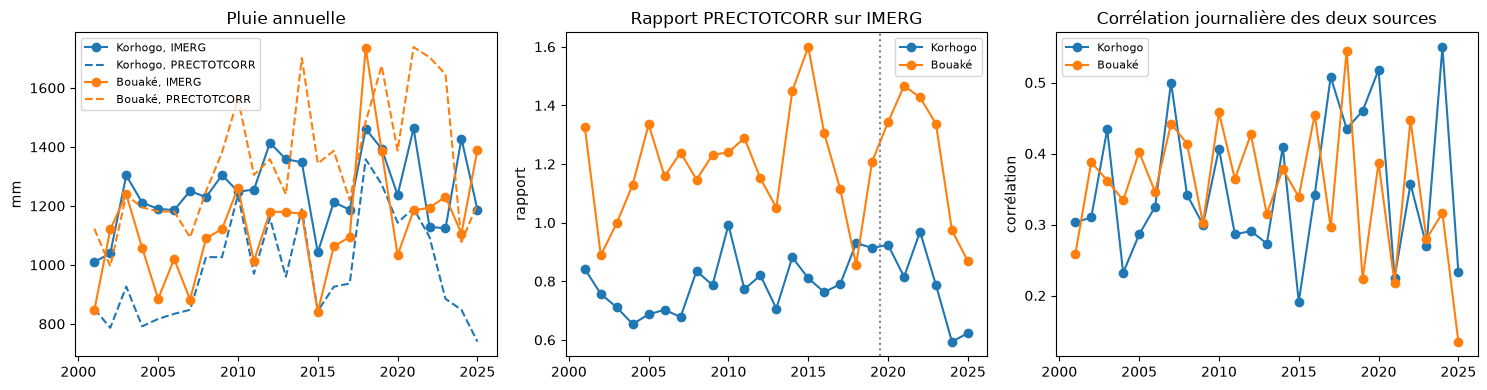

In [4]:
comparaisons = {i: comparer_pluies(s["imerg"][s["cases"][0]], s["power"]["PRECTOTCORR"]) for i, s in series.items()}
display(pd.concat({noms[i]: c for i, c in comparaisons.items()}, axis=1))
display(pd.DataFrame({noms[i]: c[["imerg_mm", "prectotcorr_mm"]].mean() for i, c in comparaisons.items()}).round(0))
display(pd.DataFrame({noms[i]: rupture_rapport(c) for i, c in comparaisons.items()}).round(3))

figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for couleur, (identifiant, c) in zip(["C0", "C1"], comparaisons.items()):
    axes[0].plot(c.index, c["imerg_mm"], color=couleur, marker="o", label=f"{noms[identifiant]}, IMERG")
    axes[0].plot(c.index, c["prectotcorr_mm"], color=couleur, linestyle="--", label=f"{noms[identifiant]}, PRECTOTCORR")
    axes[1].plot(c.index, c["rapport"], color=couleur, marker="o", label=noms[identifiant])
    axes[2].plot(c.index, c["correlation_journaliere"], color=couleur, marker="o", label=noms[identifiant])
axes[0].set(title="Pluie annuelle", ylabel="mm")
axes[1].axvline(2019.5, color="grey", linestyle=":")
axes[1].set(title="Rapport PRECTOTCORR sur IMERG", ylabel="rapport")
axes[2].set(title="Corrélation journalière des deux sources", ylabel="corrélation")
for axe in axes:
    axe.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Constat.** Le cumul annuel moyen vaut 1 248 mm selon IMERG et 986 mm selon PRECTOTCORR à Korhogo, 1 133 mm et 1 347 mm à Bouaké. Les deux sources ne désignent donc pas la même ville comme la plus arrosée, et leur corrélation journalière ne dépasse jamais 0,550 à Korhogo ni 0,545 à Bouaké selon l'année. Le rapport moyen de PRECTOTCORR à IMERG vaut 0,791 avant 2020 et 0,785 ensuite à Korhogo, 1,196 et 1,236 à Bouaké.

**Analyse.** La rupture de 2020 de PRECTOTCORR, établie sur l'Afrique par le projet antérieur, ne se lit pas à ces deux points. Le désaccord entre les deux sources est en revanche fort, sur le niveau comme sur la chronologie des pluies.

**Décision.** PRECTOTCORR n'est pas utilisé comme pluie. Son abandon repose sur ce désaccord et sur la comparaison au pluviomètre de la section suivante, plus que sur la rupture.

## 4. Comparaison aux stations GHCN-Daily

Les pluviomètres et thermomètres de Korhogo et de Bouaké sont lus dans GHCN-Daily, seule source indépendante des satellites. Leurs jours renseignés sont peu nombreux.

,"Korhogo, IVM00065536","Bouaké, IV000005555"
jours_communs,1224.000,1383.000
annees_avec_donnees,13.000,12.000
correlation_station_imerg,0.327,0.457
correlation_station_imerg_veille,0.286,0.331
correlation_station_prectotcorr,0.256,0.217
somme_station_mm,7959.300,9142.400
somme_imerg_mm,6948.020,7599.660
somme_prectotcorr_mm,6060.860,8107.960


,"Korhogo, IVM00065536","Bouaké, IV000005555"
jours_communs,2258.000,2075.000
annees_avec_donnees,14.000,14.000
ecart_moyen_merra_moins_station,0.461,0.104
correlation,0.818,0.696
part_jours_station_au_dela_de_35,0.275,0.106
part_jours_merra_au_dela_de_35,0.366,0.158


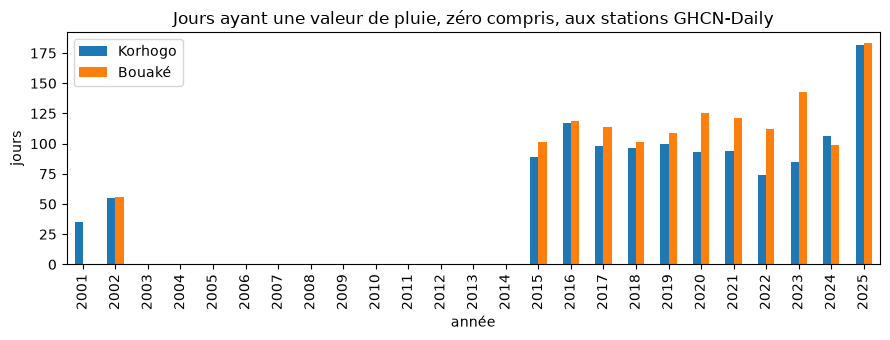

In [5]:
display(pd.DataFrame({f"{noms[i]}, {s['station']}": comparer_station(s["pluie_station"], s["imerg_station"],
                                                                          s["power"]["PRECTOTCORR"])
                      for i, s in series.items()}))
display(pd.DataFrame({f"{noms[i]}, {s['station']}": comparer_tmax_station(s["tmax_station"], s["power"]["T2M_MAX"])
                      for i, s in series.items()}))

figure, axe = plt.subplots(figsize=(9, 3.5))
jours = pd.DataFrame({noms[i]: jours_par_annee(s["pluie_station"]) for i, s in series.items()})
jours.reindex(range(2001, 2026)).plot.bar(ax=axe)
axe.set(title="Jours ayant une valeur de pluie, zéro compris, aux stations GHCN-Daily", xlabel="année", ylabel="jours")
plt.tight_layout()
plt.show()

**Constat.** Sur les jours où la station a une valeur, la corrélation journalière avec IMERG atteint 0,327 à Korhogo et 0,457 à Bouaké, contre 0,256 et 0,217 avec PRECTOTCORR. Les stations n'ont aucune donnée de 2003 à 2014 et au plus 183 jours par an. Pour la température maximale, MERRA-2 dépasse le thermomètre de 0,461 °C en moyenne à Korhogo et de 0,104 °C à Bouaké, mais compte une part de 0,366 des jours au-delà de 35 °C, soit 36,6 %, contre 0,275 à la station de Korhogo.

**Analyse.** Le pluviomètre suit mieux IMERG que PRECTOTCORR au jour le jour dans les deux villes. Ses jours ne forment pas un échantillon tiré au hasard, si bien qu'il ne dit pas quel cumul annuel est juste. Un faible biais de température suffit à gonfler un décompte au-dessus d'un seuil.

**Décision.** IMERG est retenu. Le nombre de jours au-dessus de 35 °C est remplacé par la température maximale moyenne sur le cycle des cultures, plus robuste avec MERRA-2.

## 5. Dispersion entre la case de la ville et ses huit voisines

Les neuf cases IMERG de 0,1 degré centrées sur chaque ville sont comparées par année.

,Korhogo,Bouaké
annees_avant,12,12
premiere_avant,1,0
annees_apres,13,13
premiere_apres,11,9


Korhogo


,ecart_moyen_mm,ecart_moyen_pct,ecart_min_pct,ecart_max_pct
2001-2012,9.0,0.7,-2.5,3.9
2013-2025,89.2,7.6,-1.7,12.6
2001-2025,50.7,4.3,-2.5,12.6


Bouaké


,ecart_moyen_mm,ecart_moyen_pct,ecart_min_pct,ecart_max_pct
2001-2012,-5.9,-0.6,-2.7,1.6
2013-2025,50.5,4.3,0.7,7.4
2001-2025,23.4,2.0,-2.7,7.4


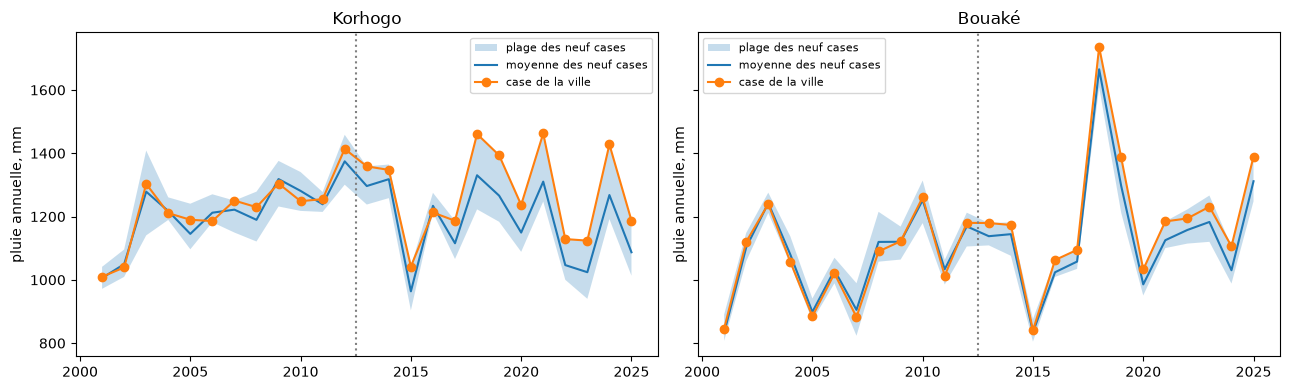

In [6]:
dispersions = {i: dispersion_voisinage(s["imerg"]) for i, s in series.items()}
display(pd.DataFrame({noms[i]: case_la_plus_arrosee(d) for i, d in dispersions.items()}))
for identifiant, d in dispersions.items():
    print(noms[identifiant])
    display(ecart_case_moyenne(d))

figure, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axe, (identifiant, d) in zip(axes, dispersions.items()):
    axe.fill_between(d.index, d["min_9_cases_mm"], d["max_9_cases_mm"], alpha=0.25, label="plage des neuf cases")
    axe.plot(d.index, d["moyenne_9_cases_mm"], label="moyenne des neuf cases")
    axe.plot(d.index, d["case_du_lieu_mm"], marker="o", label="case de la ville")
    axe.axvline(2012.5, color="grey", linestyle=":")
    axe.set(title=noms[identifiant], ylabel="pluie annuelle, mm")
    axe.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Constat.** La case de la ville est la plus arrosée des neuf 1 année sur 12 de 2001 à 2012 et 11 années sur 13 de 2013 à 2025 à Korhogo, 0 sur 12 puis 9 sur 13 à Bouaké. Depuis 2013, elle dépasse la moyenne des neuf cases de 7,6 % en moyenne à Korhogo, jusqu'à 12,6 %, et de 4,3 % à Bouaké, contre moins de 1 % avant.

**Analyse.** Le hasard donnerait une année sur neuf. La cause reste inconnue, effet urbain réel ou artefact du produit. La seule case de la ville ferait croire à une hausse de la pluie que les cases voisines ne confirment pas.

**Décision.** La pluie d'un lieu est la moyenne des neuf cases, décision du responsable du 14 novembre 2026, et la dispersion entre cases sert de mesure d'incertitude spatiale.

## 6. Calendrier des pluies

La pluie mensuelle moyenne de la case de chaque ville est donnée avec ses quantiles 10 et 90 % entre années.

Korhogo                   Bouaké              
     moyenne_mm q10_mm q90_mm moyenne_mm q10_mm q90_mm
date                                                  
1          13.9    0.2   35.7       12.9    0.8   29.4
2          23.1    2.3   51.1       51.0   18.3  116.8
3          44.0   22.8   77.8       96.8   55.5  135.6
4          88.1   53.7  121.7      122.2   98.7  157.6
5         107.2   60.1  141.7      129.9   85.8  169.9
6         141.4  101.5  185.1      137.5   76.4  204.1
7         195.2  123.7  266.8       92.6   46.8  148.6
8         233.0  173.2  290.9      125.3   55.6  210.9
9         239.0  170.8  310.3      166.6  104.2  213.7
10        120.7   60.9  183.1      143.0   75.8  208.5
11         25.6    5.9   45.7       37.4    6.3   64.8
12         17.3    1.3   44.4       18.0    3.8   33.5

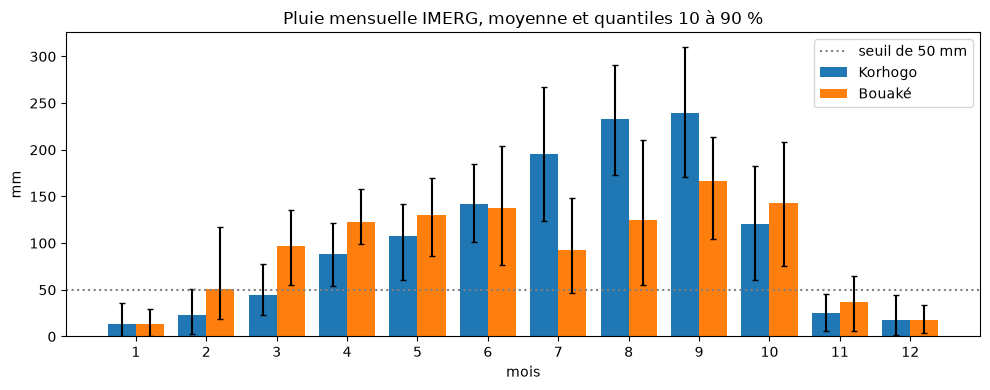

In [7]:
climatologies = {i: climatologie_mensuelle(s["imerg"][s["cases"][0]]) for i, s in series.items()}
display(pd.concat({noms[i]: c for i, c in climatologies.items()}, axis=1))

figure, axe = plt.subplots(figsize=(10, 4))
largeur = 0.4
for decalage, (identifiant, c) in zip([-largeur / 2, largeur / 2], climatologies.items()):
    axe.bar(c.index + decalage, c["moyenne_mm"], width=largeur, label=noms[identifiant],
            yerr=[c["moyenne_mm"] - c["q10_mm"], c["q90_mm"] - c["moyenne_mm"]], capsize=2)
axe.axhline(50, color="grey", linestyle=":", label="seuil de 50 mm")
axe.set(title="Pluie mensuelle IMERG, moyenne et quantiles 10 à 90 %", xlabel="mois", ylabel="mm", xticks=range(1, 13))
axe.legend()
plt.tight_layout()
plt.show()

**Constat.** À Korhogo, la pluie mensuelle moyenne dépasse 50 mm d'avril, 88,1 mm, à octobre, 120,7 mm, avec un maximum de 239,0 mm en septembre. Bouaké dépasse 50 mm de février à octobre, avec un creux en juillet, 92,6 mm, entre juin, 137,5 mm, et août, 125,3 mm.

**Analyse.** Le calendrier de Korhogo concorde avec la saison d'avril ou mai à octobre décrite par Zagbaï et collègues avec ce même seuil de 50 mm. Le creux de juillet de Bouaké montre ses deux saisons des pluies.

**Décision.** Le début de saison est cherché à partir du 1er mars dans les deux villes, et seule la première saison de Bouaké est traitée, ce que la phase 3 précise.

## 7. Données de surface

**Constat.** SMAP, MODIS MCD12Q1 et MOD13Q1 et SRTM figurent au catalogue d'AppEEARS, qui demande un compte NASA Earthdata. SoilGrids répond sans compte, mais sa valeur est vide au centre de Korhogo, et un pixel MODIS au centre-ville couvre la ville.

**Analyse.** Les sols et la végétation doivent être lus sur des points cultivés autour de chaque ville, pixels MCD12Q1 de classes 12 et 14 de la couche IGBP.

**Décision.** Les extractions attendent le compte Earthdata du responsable. Ce notebook sera complété quand elles seront faites.